In [127]:
import torch
import numpy as  np
import pandas as pd
import torch.nn as nn
import matplotlib.pyplot as plt
import sklearn.datasets as Dataset

In [128]:
iris = Dataset.load_iris()

In [129]:
X = iris.data
Y = iris.target
print(type(X))

<class 'numpy.ndarray'>


In [130]:
inpot = torch.from_numpy(X.astype(np.float32))
target = torch.from_numpy(Y.astype(np.int64))

### creat modle

In [131]:
model = nn.Sequential(
    nn.Linear(4,16)
,nn.ReLU()
,nn.Linear(16,8)
,nn.ReLU()
,nn.Linear(8,3)
)


### loss & optimizer

In [132]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(),lr = 0.05)

### train loop

In [133]:
n_epochs = 300
losses = []
for epoch in range(n_epochs):
  # zero grad
  optimizer.zero_grad()

  #Forwardpass
  output  = model(inpot)
  loss = criterion(output,target)

  #save losses
  losses.append(loss.item())

  #backward
  loss.backward()
  optimizer.step()
  if epoch % 10 == 0 :
    print(f'Epoch = {epoch} /{n_epochs}  , Loss : {loss.item() :.4f}')



Epoch = 0 /300  , Loss : 1.3094
Epoch = 10 /300  , Loss : 1.0662
Epoch = 20 /300  , Loss : 0.9916
Epoch = 30 /300  , Loss : 0.9027
Epoch = 40 /300  , Loss : 0.7912
Epoch = 50 /300  , Loss : 0.6700
Epoch = 60 /300  , Loss : 0.5713
Epoch = 70 /300  , Loss : 0.5019
Epoch = 80 /300  , Loss : 0.4504
Epoch = 90 /300  , Loss : 0.4075
Epoch = 100 /300  , Loss : 0.3685
Epoch = 110 /300  , Loss : 0.3315
Epoch = 120 /300  , Loss : 0.2967
Epoch = 130 /300  , Loss : 0.4948
Epoch = 140 /300  , Loss : 0.3808
Epoch = 150 /300  , Loss : 0.3541
Epoch = 160 /300  , Loss : 0.3550
Epoch = 170 /300  , Loss : 0.3467
Epoch = 180 /300  , Loss : 0.3358
Epoch = 190 /300  , Loss : 0.3260
Epoch = 200 /300  , Loss : 0.3177
Epoch = 210 /300  , Loss : 0.3093
Epoch = 220 /300  , Loss : 0.2994
Epoch = 230 /300  , Loss : 0.2898
Epoch = 240 /300  , Loss : 0.2804
Epoch = 250 /300  , Loss : 0.2718
Epoch = 260 /300  , Loss : 0.2537
Epoch = 270 /300  , Loss : 0.2518
Epoch = 280 /300  , Loss : 0.2284
Epoch = 290 /300  , Loss 

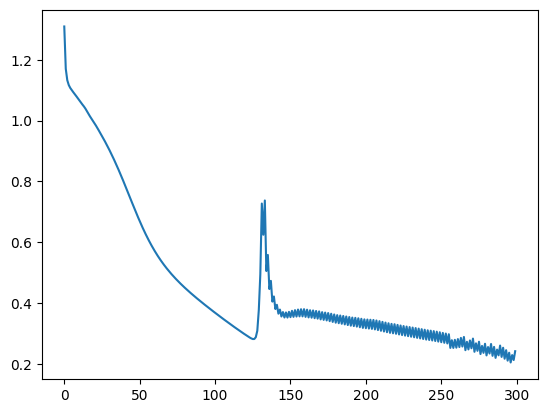

In [134]:
plt.plot(losses)

In [135]:
output.shape

torch.Size([150, 3])

In [144]:
# correct = 0
# for i  in range(output.shape[0]):
#   if torch.argmax(output[i]) == target[i]:
#     correct +=1
# accuracy = correct  / 150
# accuracy
predictions = torch.argmax(output,dim = 1)
accuracy = (predictions == target).float().mean().item()
accuracy

0.8799999952316284

0.88